# Hybrid 1D-CNN + LSTM Intrusion Detection System — **Bot-IoT** edition

This notebook mirrors the UNSW-NB15 pipeline exactly (same three models, same
leakage-free discipline, same edge-readiness metrics, same TFLite export) but
trains and evaluates on the **Bot-IoT** dataset.

**Key methodological difference vs UNSW-NB15.** Bot-IoT's class imbalance is
*reversed*: attack traffic dominates and Normal traffic is the rare minority.
Three consequences follow, and the pipeline is built around them:

1. **SMOTE now oversamples the *Normal* class** (the code auto-balances whichever
   class is the minority, so no logic change is needed — only the interpretation).
2. **Raw accuracy is misleading.** A trivial "always-attack" classifier can score
   ~99% on Bot-IoT. **MCC, the Normal-class recall, and AUC are the decisive
   metrics** here, exactly the ones the report already emphasises.
3. **Leakage control is stricter.** The Luqman et al. (2025) Bot-IoT study shows
   the destination-IP feature alone reaches >0.25 importance and single-handedly
   causes overfitting, so every host / port / time / MAC identifier is dropped
   before any learning — the same principle used for UNSW.


In [ ]:
# ============================================================
# CELL 1 — Environment setup (mount Drive + install imblearn)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import importlib
if importlib.util.find_spec('imblearn') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])

print('Environment ready.')

Mounted at /content/drive
Environment ready.


In [ ]:
# ============================================================
# CELL 2 — Configuration  <- edit paths here only
# ============================================================
import os

BOT_PATHS = [
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_1.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_2.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_3.csv',
    '/content/drive/MyDrive/FYP_Project/data/Bot_iot dataset/reduced_data_4.csv',
]
BOT_ROWS_PER_FILE = 100_000

OUTPUT_DIR = '/content/drive/MyDrive/FYP_Project/models_botiot'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----- Bot-IoT schema knowledge (from Luqman et al. 2025 + UNSW NB15 dataset docs) -----
# Identifier / leaky columns: dropped BEFORE any learning so the model generalises
# to flow BEHAVIOUR, not to specific hosts, ports, capture times, or NIC addresses.
#   saddr,daddr        -> IP addresses        (host-identity leak; daddr alone overfits)
#   sport,dport        -> ports               (weak identity leak; often hex / >550 nulls)
#   stime,ltime        -> absolute timestamps (temporal leak)
#   pkSeqID,seq        -> packet/sequence IDs (row-order leak)
#   smac,dmac,soui,doui,sco,dco -> MAC / org identifiers (host-identity leak)
#   category,subcategory        -> attack sub-labels (target leak for the binary task)
LEAKY_COLS = [
    'saddr', 'daddr', 'sport', 'dport', 'stime', 'ltime', 'pkseqid', 'seq',
    'smac', 'dmac', 'soui', 'doui', 'sco', 'dco', 'category', 'subcategory',
]
# Nominal fields -> One-Hot Encoded (never label-encoded: that injects false ordinality).
CATEGORICAL_CANDIDATES = ['proto', 'flgs', 'state']
# Binary target column (Bot-IoT uses 'attack'; fall back to 'label' if renamed).
LABEL_CANDIDATES = ['attack', 'label']

# Shared hyperparameters — identical for all three models (fair comparison),
# and identical to the UNSW-NB15 notebook for a like-for-like cross-dataset study.
BATCH_SIZE  = 128
EPOCHS      = 30
PATIENCE    = 5
TEST_SIZE   = 0.20
VAL_SPLIT   = 0.15
RANDOM_SEED = 42
TARGET_K_FEATURES = 20      # ANOVA top-K (capped to whatever survives preprocessing)

print('Configuration loaded.')
print(f'All models trained with: batch={BATCH_SIZE}, max_epochs={EPOCHS}, patience={PATIENCE}')

Configuration loaded.
All models trained with: batch=128, max_epochs=30, patience=5


In [ ]:
# ============================================================
# CELL 3 — Imports + reproducibility
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, confusion_matrix, roc_curve, auc, classification_report,
)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D, GlobalAveragePooling1D,
    LSTM, Dense, Dropout,
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print('TensorFlow version:', tf.__version__)
print('GPU available     :', bool(tf.config.list_physical_devices('GPU')))

TensorFlow version: 2.20.0
GPU available     : True


In [ ]:
# ============================================================
# CELL 4 — PHASE 1.1 : Load Bot-IoT (header auto-detected)
# ============================================================
# Unlike the raw UNSW-NB15 files (which carry NO header), the Bot-IoT reduced
# CSVs normally ship WITH a header row. We auto-detect it so the loader works
# either way, then standardise column names to lower-case for robust matching.
def _has_header(path):
    """Heuristic: first line is a header if it contains known Bot-IoT field names."""
    with open(path, 'r', errors='ignore') as f:
        first = f.readline().lower()
    known = ('pkseqid', 'saddr', 'proto', 'attack', 'stime', 'sport', 'bytes', 'pkts')
    return any(tok in first for tok in known)

def load_botiot(paths):
    frames = []
    for p in paths:
        if not os.path.exists(p):
            print(f'  [WARN] missing file skipped: {p}')
            continue
        hdr = 0 if _has_header(p) else None
        df = pd.read_csv(p, header=hdr, low_memory=False)   # FULL file — no top-N slice
        df.columns = [str(c).strip().lower() for c in df.columns]
        frames.append(df)
        print(f'  loaded {len(df):>7,} rows from {os.path.basename(p)}')
    if not frames:
        raise FileNotFoundError('No Bot-IoT files found — check CELL 2 paths.')
    return pd.concat(frames, ignore_index=True, sort=False)

print('Loading Bot-IoT (full files) ...')
df = load_botiot(BOT_PATHS)
print(f'Combined raw shape: {df.shape}')

label_col = next((c for c in LABEL_CANDIDATES if c in df.columns), None)
if label_col is None:
    raise KeyError(f'No label column found among {LABEL_CANDIDATES}. Got {list(df.columns)}')

# Normalise label to binary and CHECK whether Normal exists at all.
y_tmp = (pd.to_numeric(df[label_col], errors='coerce').fillna(0) > 0).astype(int)
print('Full-file class balance:'); print(y_tmp.value_counts())
assert (y_tmp == 0).sum() > 0, \
    'No Normal rows exist in these files — you need the Bot-IoT normal traffic CSV.'

# Build a tractable, TWO-class working set: keep ALL Normal, sample Attack down.
ATTACK_PER_NORMAL = 3                       # 1:3 Normal:Attack (tune as you like)
normal_idx = df.index[y_tmp == 0]
attack_idx = df.index[y_tmp == 1]
n_keep = min(len(attack_idx), len(normal_idx) * ATTACK_PER_NORMAL)
rng = np.random.RandomState(RANDOM_SEED)
attack_sample = rng.choice(attack_idx, size=n_keep, replace=False)

keep = normal_idx.union(pd.Index(attack_sample))
df = df.loc[keep].sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

print(f'Working set: {df.shape} | Normal={len(normal_idx):,} Attack(kept)={n_keep:,}')
print('Class balance (0=Normal, 1=Attack):')
print(df[label_col].value_counts(normalize=True).rename("proportion"))

Loading Bot-IoT (full files) ...
  loaded 1,000,000 rows from reduced_data_1.csv
  loaded 1,000,000 rows from reduced_data_2.csv
  loaded 1,000,000 rows from reduced_data_3.csv
  loaded 668,522 rows from reduced_data_4.csv
Combined raw shape: (3668522, 46)
Full-file class balance:
attack
1    3668045
0        477
Name: count, dtype: int64
Working set: (1908, 46) | Normal=477 Attack(kept)=1,431
Class balance (0=Normal, 1=Attack):
attack
1    0.75
0    0.25
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# CELL 5 — PHASE 1.1 : Drop leaky / identifier columns
# ============================================================
present_leaks = [c for c in LEAKY_COLS if c in df.columns]
df = df.drop(columns=present_leaks)

TARGET = label_col
y_all = pd.to_numeric(df[TARGET], errors='coerce').fillna(0).astype(int)
# Some Bot-IoT exports store attack as >1 for malicious — clamp to binary {0,1}.
y_all = (y_all > 0).astype(int)
X_all = df.drop(columns=[TARGET])

print(f'After dropping leaks -> features: {X_all.shape[1]}, samples: {X_all.shape[0]}')
print('Dropped:', present_leaks)

# Reversed-imbalance sanity check (Bot-IoT specific).
n_norm = int((y_all == 0).sum()); n_att = int((y_all == 1).sum())
print(f'Normal={n_norm:,}  |  Attack={n_att:,}')
if min(n_norm, n_att) < 50:
    print('  [WARNING] The minority class has <50 samples. SMOTE will still run, '
          'but consider loading more rows so the minority is better represented.')

After dropping leaks -> features: 35, samples: 1908
Dropped: ['saddr', 'daddr', 'sport', 'dport', 'stime', 'ltime', 'pkseqid', 'seq', 'category', 'subcategory']
Normal=477  |  Attack=1,431


In [ ]:
# ============================================================
# CELL 6 — PHASE 1.2/1.3 : Clean, impute, one-hot encode
# ============================================================
# Categoricals = the nominal fields that actually exist AND are non-numeric.
CATEGORICAL_COLS = [
    c for c in CATEGORICAL_CANDIDATES
    if c in X_all.columns and not pd.api.types.is_numeric_dtype(X_all[c])
]
NUMERIC_COLS = [c for c in X_all.columns if c not in CATEGORICAL_COLS]

# Coerce numeric fields (Bot-IoT sometimes stores numbers as strings / hex blanks).
for c in NUMERIC_COLS:
    X_all[c] = pd.to_numeric(X_all[c], errors='coerce')

# Drop numeric columns that are entirely empty after coercion (no signal).
empty_cols = [c for c in NUMERIC_COLS if X_all[c].isna().all()]
if empty_cols:
    X_all = X_all.drop(columns=empty_cols)
    NUMERIC_COLS = [c for c in NUMERIC_COLS if c not in empty_cols]
    print('Dropped all-empty numeric columns:', empty_cols)

# Normalise categorical text; guard against accidental high-cardinality blow-up.
safe_cat = []
for c in CATEGORICAL_COLS:
    X_all[c] = X_all[c].astype(str).str.strip().replace({'': '-', 'nan': '-'})
    if X_all[c].nunique() <= 50:
        safe_cat.append(c)
    else:
        print(f'  [skip OHE] "{c}" has {X_all[c].nunique()} categories (>50) — treated as dropped.')
        X_all = X_all.drop(columns=[c])
CATEGORICAL_COLS = safe_cat

# --- Stratified 80/20 split BEFORE fitting anything (no leakage) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_SEED,
)
print(f'Train: {X_train_raw.shape[0]:,}  |  Test: {X_test_raw.shape[0]:,}')

# --- Imputation: learn statistics on TRAIN ONLY, apply to both ---
num_medians = X_train_raw[NUMERIC_COLS].median()
X_train_raw[NUMERIC_COLS] = X_train_raw[NUMERIC_COLS].fillna(num_medians)
X_test_raw[NUMERIC_COLS]  = X_test_raw[NUMERIC_COLS].fillna(num_medians)
if CATEGORICAL_COLS:
    cat_modes = X_train_raw[CATEGORICAL_COLS].mode().iloc[0]
    X_train_raw[CATEGORICAL_COLS] = X_train_raw[CATEGORICAL_COLS].fillna(cat_modes)
    X_test_raw[CATEGORICAL_COLS]  = X_test_raw[CATEGORICAL_COLS].fillna(cat_modes)

# --- One-Hot Encoding (test reindexed to TRAIN vocabulary) ---
X_train_enc = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLS)
X_test_enc  = pd.get_dummies(X_test_raw,  columns=CATEGORICAL_COLS)
X_test_enc  = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

X_train_enc = X_train_enc.astype('float32')
X_test_enc  = X_test_enc.astype('float32')

feature_names = X_train_enc.columns.to_numpy()
print(f'Categorical (OHE): {CATEGORICAL_COLS}')
print(f'Features after One-Hot Encoding: {X_train_enc.shape[1]}')

Train: 1,526  |  Test: 382
Categorical (OHE): ['proto', 'flgs', 'state']
Features after One-Hot Encoding: 50


In [ ]:
# ============================================================
# CELL 7 — PHASE 1.5 : MinMax scaling (fit on TRAIN only)
# ============================================================
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled  = scaler.transform(X_test_enc)
print('Scaling complete. Range now [0, 1] for all features.')

Scaling complete. Range now [0, 1] for all features.


In [ ]:
# ============================================================
# CELL 8 — PHASE 2 : ANOVA F-test feature selection (top-K)
# ============================================================
# Fit SelectKBest on the REAL, pre-SMOTE training set (fitting on synthetic
# samples would bias F-scores). Carry the SAME K columns to the test set.
k = min(TARGET_K_FEATURES, X_train_scaled.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_train_sel = selector.fit_transform(X_train_scaled, y_train)
X_test_sel  = selector.transform(X_test_scaled)

selected_feature_names = feature_names[selector.get_support()]
print(f'Selected {k} / {X_train_scaled.shape[1]} features via ANOVA F-test.')
print('Top features:', list(selected_feature_names))

Selected 20 / 50 features via ANOVA F-test.
Top features: ['proto_number', 'dur', 'mean', 'stddev', 'sum', 'max', 'tnbpsrcip', 'tnbpdstip', 'tnp_psrcip', 'tnp_pdstip', 'tnp_perproto', 'n_in_conn_p_dstip', 'n_in_conn_p_srcip', 'proto_arp', 'proto_tcp', 'flgs_e', 'flgs_e s', 'state_CON', 'state_REQ', 'state_RST']


In [ ]:
# ==========================================================================
# Cell 8b — Export preprocess.json  (BoT-IoT fitted transform)
# --------------------------------------------------------------------------
# Mirrors the UNSW export but for THIS pipeline's variables: 20 selected
# features, 'flgs'/'proto'/'state' categoricals, per-IP leaky columns dropped.
# Run AFTER Cell 8 (scaler + selector fitted), BEFORE SMOTE.
# ==========================================================================
import json

# cat_modes only exists if any categoricals survived preprocessing (this
# notebook drops unsafe/empty categoricals dynamically), so guard for it.
cat_modes_dict = {}
if CATEGORICAL_COLS:
    cat_modes_dict = {str(k): str(v) for k, v in cat_modes.items()}

preprocess = {
    'dataset'               : 'BoT-IoT',
    'leaky_cols'            : list(LEAKY_COLS),
    'categorical_cols'      : list(CATEGORICAL_COLS),
    'numeric_medians'       : {str(k): float(v) for k, v in num_medians.items()},
    'cat_modes'             : cat_modes_dict,
    'ohe_vocab'             : [str(c) for c in feature_names],
    'scaler_min'            : [float(x) for x in scaler.data_min_],
    'scaler_max'            : [float(x) for x in scaler.data_max_],
    'selected_feature_names': [str(c) for c in selected_feature_names],
}

assert len(preprocess['ohe_vocab']) == len(preprocess['scaler_min']) == \
       len(preprocess['scaler_max']), 'scaler length must match ohe_vocab'
assert all(f in preprocess['ohe_vocab']
           for f in preprocess['selected_feature_names']), \
       'every selected feature must be in ohe_vocab'
assert len(preprocess['selected_feature_names']) == X_train_sel.shape[1], \
       'selected count must equal model input width'

out_path = f'{OUTPUT_DIR}/preprocess.json'
with open(out_path, 'w') as f:
    json.dump(preprocess, f, indent=2)

print(f'[✓] Wrote {out_path}')
print(f'    ohe_vocab: {len(preprocess["ohe_vocab"])} cols  |  '
      f'selected: {len(preprocess["selected_feature_names"])} features')

[✓] Wrote /content/drive/MyDrive/FYP_Project/models_botiot/preprocess.json
    ohe_vocab: 50 cols  |  selected: 20 features


In [ ]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# ============================================================
# CELL 9 — PHASE 1.6 : SMOTE on the TRAINING set only
# ============================================================
# On Bot-IoT this oversamples the *Normal* class (the minority). The test set
# keeps its real, imbalanced distribution for an honest evaluation.
before = dict(pd.Series(y_train).value_counts())
print('Before SMOTE:', before)

if len(before) < 2:
    print('[WARNING] SMOTE skipped: Only one class found in y_train. Expected at least two classes for oversampling.')
    X_train_bal, y_train_bal = X_train_sel, y_train
else:
    n_minority = min(before.values())
    k_neighbors = max(1, min(5, n_minority - 1))   # guard tiny minority class
    smote = SMOTE(random_state=RANDOM_SEED, k_neighbors=k_neighbors)
    X_train_bal, y_train_bal = smote.fit_resample(X_train_sel, y_train)
    print('After  SMOTE:', dict(pd.Series(y_train_bal).value_counts()))

Before SMOTE: {1: np.int64(1145), 0: np.int64(381)}
After  SMOTE: {1: np.int64(1145), 0: np.int64(1145)}


In [ ]:
# ============================================================
# CELL 10 — PHASE 3 : Reshape 2D -> 3D for Conv1D / LSTM
# ============================================================
N_FEATURES = X_train_bal.shape[1]
X_train_3d = X_train_bal.reshape(-1, N_FEATURES, 1).astype('float32')
X_test_3d  = X_test_sel.reshape(-1,  N_FEATURES, 1).astype('float32')
y_train_bal = np.asarray(y_train_bal).astype('float32')
y_test_arr  = np.asarray(y_test).astype('float32')

INPUT_SHAPE = (N_FEATURES, 1)
print(f'Train tensor: {X_train_3d.shape}  |  Test tensor: {X_test_3d.shape}')

Train tensor: (2290, 20, 1)  |  Test tensor: (382, 20, 1)


In [ ]:
# ============================================================
# CELL 11 — PHASE 4 : Model builders (Updated with unroll=True for TFLite compatibility)
# ============================================================
def build_cnn(input_shape):
    """Baseline 1: Standalone 1D CNN."""
    model = Sequential(name='Standalone_1D_CNN')
    model.add(Input(shape=input_shape))
    model.add(Conv1D(64,  kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Conv1D(128, kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(GlobalAveragePooling1D())
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_lstm(input_shape):
    """Baseline 2: Stacked LSTM (unrolled for TFLite)."""
    model = Sequential(name='Stacked_LSTM')
    model.add(Input(shape=input_shape))
    model.add(LSTM(128, return_sequences=True, unroll=True))
    model.add(Dropout(0.3))
    model.add(LSTM(32,  return_sequences=False, unroll=True))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_hybrid(input_shape):
    """Target Model: Hybrid 1D CNN + LSTM (unrolled for TFLite)."""
    model = Sequential(name='Hybrid_CNN_LSTM')
    model.add(Input(shape=input_shape))
    model.add(Conv1D(64, kernel_size=3, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.2))
    model.add(LSTM(64, return_sequences=False, unroll=True))
    model.add(Dropout(0.3))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
# ============================================================
# CELL 12 — PHASE 5 : Callbacks + unified training routine
# ============================================================
def make_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=PATIENCE,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=3, min_lr=1e-6, verbose=1),
    ]


def train_model(build_fn, name):
    print('\n' + '=' * 60)
    print(f'TRAINING: {name}')
    print('=' * 60)
    model = build_fn(INPUT_SHAPE)
    model.summary()
    history = model.fit(
        X_train_3d, y_train_bal,
        validation_split=VAL_SPLIT,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=make_callbacks(),
        verbose=1,
    )
    return model, history


cnn_model,    cnn_hist    = train_model(build_cnn,    'Standalone 1D CNN')
lstm_model,   lstm_hist   = train_model(build_lstm,   'Stacked LSTM')
hybrid_model, hybrid_hist = train_model(build_hybrid, 'Hybrid CNN-LSTM')


TRAINING: Standalone 1D CNN


Model: "Standalone_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 20, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 20, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,049 (133.00 KB)

 Trainable params: 33,665 (131.50 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 20, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,649 (139.25 KB)

 Trainable params: 35,521 (138.75 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 674ms/step - accuracy: 0.6850 - loss: 0.6034 - val_accuracy: 0.0000e+00 - val_loss: 0.7997 - learning_rate: 0.0010
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9368 - loss: 0.2946 - val_accuracy: 0.6715 - val_loss: 0.7606 - learning_rate: 0.0010
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9676 - loss: 0.1210 - val_accuracy: 0.8692 - val_loss: 0.6188 - learning_rate: 0.0010
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9825 - loss: 0.0775 - val_accuracy: 0.8692 - val_loss: 0.5650 - learning_rate: 0.0010
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9836 - loss: 0.0692 - val_accuracy: 0.8692 - val_loss: 0.4802 - learning_rate: 0.0010
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9841 - loss: 0.0556 - val_accuracy: 0.9070 - val_loss: 0.3347 - learning_rate: 0.0010
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9897 - loss: 0.0363 - val_ac

In [ ]:
# ============================================================
# CELL 13 — PHASE 6.3 : Edge-readiness metric helpers
# ============================================================
def measure_latency_ms(model, sample, n_runs=200, warmup=20):
    """Average single-flow inference latency in milliseconds (compiled call, bypasses Keras predict() overhead)."""
    x = tf.constant(sample.reshape(1, *sample.shape))
    infer = tf.function(lambda inp: model(inp, training=False))
    for _ in range(warmup):
        infer(x)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        infer(x)
    return (time.perf_counter() - t0) / n_runs * 1000.0

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# ============================================================
# CELL 14 — PHASE 6.1 : Evaluate + collect all metrics
# ============================================================
# NOTE (Bot-IoT): because attacks dominate the test set, READ MCC, AUC, and the
# per-class report (especially Normal recall) — NOT headline accuracy.

def model_size_kb(model):
    """Returns the estimated size of a Keras model in kilobytes (assuming float32 parameters)."""
    total_params = model.count_params()
    return (total_params * 4) / 1024  # Assuming float32 (4 bytes per param)

def evaluate_model(model, name):
    y_prob = model.predict(X_test_3d, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    fpr, tpr, _ = roc_curve(y_test_arr, y_prob)
    roc_auc = auc(fpr, tpr)

    metrics = {
        'name'      : name,
        'accuracy'  : accuracy_score(y_test_arr, y_pred),
        'precision' : precision_score(y_test_arr, y_pred, zero_division=0),
        'recall'    : recall_score(y_test_arr, y_pred, zero_division=0),
        'f1'        : f1_score(y_test_arr, y_pred, zero_division=0),
        'mcc'       : matthews_corrcoef(y_test_arr, y_pred),
        'auc'       : roc_auc,
        'cm'        : confusion_matrix(y_test_arr, y_pred),
        'fpr'       : fpr,
        'tpr'       : tpr,
        'params'    : model.count_params(),
        'size_kb'   : model_size_kb(model),
        'latency_ms': measure_latency_ms(model, X_test_3d[0]),
    }
    print(f'\n--- {name} ---')
    print(classification_report(y_test_arr, y_pred,
                                target_names=['Normal', 'Attack'], digits=4))
    return metrics


results = [
    evaluate_model(cnn_model,    'Standalone 1D CNN'),
    evaluate_model(lstm_model,   'Stacked LSTM'),
    evaluate_model(hybrid_model, 'Hybrid CNN-LSTM'),
]


--- Standalone 1D CNN ---
              precision    recall  f1-score   support

      Normal     0.5926    1.0000    0.7442        96
      Attack     1.0000    0.7692    0.8696       286

    accuracy                         0.8272       382
   macro avg     0.7963    0.8846    0.8069       382
weighted avg     0.8976    0.8272    0.8381       382


--- Stacked LSTM ---
              precision    recall  f1-score   support

      Normal     0.9895    0.9792    0.9843        96
      Attack     0.9930    0.9965    0.9948       286

    accuracy                         0.9921       382
   macro avg     0.9913    0.9878    0.9895       382
weighted avg     0.9921    0.9921    0.9921       382


--- Hybrid CNN-LSTM ---
              precision    recall  f1-score   support

      Normal     0.9897    1.0000    0.9948        96
      Attack     1.0000    0.9965    0.9982       286

    accuracy                         0.9974       382
   macro avg     0.9948    0.9983    0.9965       382


In [ ]:
# ============================================================
# CELL 15 — PHASE 6.1/6.3 : Unified comparison report
# ============================================================
report = pd.DataFrame([{
    'Model'        : r['name'],
    'Accuracy'     : r['accuracy'],
    'Precision'    : r['precision'],
    'Recall'       : r['recall'],
    'F1-Score'     : r['f1'],
    'MCC'          : r['mcc'],
    'AUC'          : r['auc'],
    'Params'       : r['params'],
    'Size (KB)'    : r['size_kb'],
    'Latency (ms)' : r['latency_ms'],
} for r in results])

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
print('\n' + '=' * 70)
print('UNIFIED MODEL COMPARISON  (Bot-IoT, test = 20% unseen, imbalanced)')
print('=' * 70)
print(report.to_string(index=False))

report.to_csv(os.path.join(OUTPUT_DIR, 'ids_comparison_report_botiot.csv'), index=False)
print(f'\nReport saved to {OUTPUT_DIR}/ids_comparison_report_botiot.csv')


UNIFIED MODEL COMPARISON  (Bot-IoT, test = 20% unseen, imbalanced)
            Model  Accuracy  Precision  Recall  F1-Score    MCC    AUC  Params  Size (KB)  Latency (ms)
Standalone 1D CNN    0.8272     1.0000  0.7692    0.8696 0.6752 1.0000   34049   133.0039        0.9820
     Stacked LSTM    0.9921     0.9930  0.9965    0.9948 0.9791 0.9980   89345   349.0039        5.2040
  Hybrid CNN-LSTM    0.9974     1.0000  0.9965    0.9982 0.9931 1.0000   35649   139.2539        1.9759

Report saved to /content/drive/MyDrive/FYP_Project/models_botiot/ids_comparison_report_botiot.csv


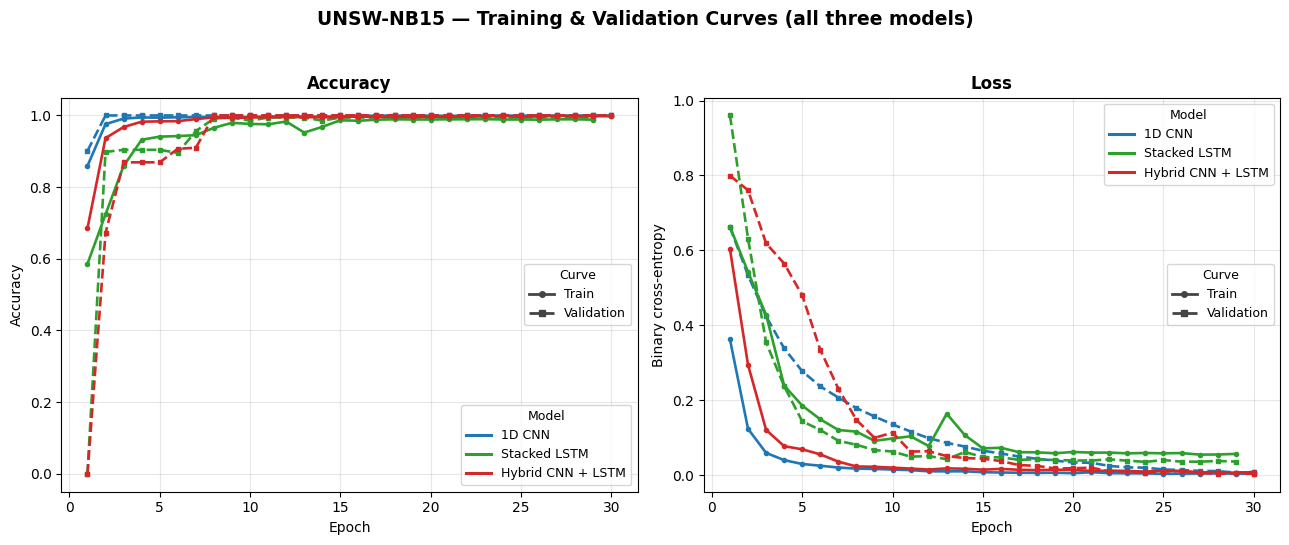

In [ ]:
# ============================================================
# Training & validation curves — all three models overlaid
# Run AFTER the training cell (needs cnn_hist / lstm_hist / hybrid_hist)
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- set this per notebook: 'UNSW-NB15' or 'BoT-IoT' ---
DATASET_NAME = 'UNSW-NB15'

MODELS = {                              # label -> (History, colour)
    '1D CNN':            (cnn_hist,    '#1f77b4'),
    'Stacked LSTM':      (lstm_hist,   '#2ca02c'),
    'Hybrid CNN + LSTM': (hybrid_hist, '#d62728'),
}

def _h(hist):   return hist.history if hasattr(hist, 'history') else hist
def _key(hd, *names):
    for n in names:
        if n in hd: return hd[n]
    raise KeyError(f"none of {names} in {list(hd.keys())}")

fig, (axA, axL) = plt.subplots(1, 2, figsize=(13, 5.4))
for label, (hist, c) in MODELS.items():
    hd = _h(hist)
    acc  = _key(hd, 'accuracy', 'acc');   vacc  = _key(hd, 'val_accuracy', 'val_acc')
    loss = _key(hd, 'loss');              vloss = _key(hd, 'val_loss')
    x = range(1, len(acc) + 1)
    axA.plot(x, acc,  '-',  color=c, lw=1.9, marker='o', ms=3)
    axA.plot(x, vacc, '--', color=c, lw=1.9, marker='s', ms=3)
    axL.plot(x, loss, '-',  color=c, lw=1.9, marker='o', ms=3)
    axL.plot(x, vloss,'--', color=c, lw=1.9, marker='s', ms=3)

axA.set_title('Accuracy', fontsize=12, fontweight='bold')
axA.set_xlabel('Epoch'); axA.set_ylabel('Accuracy'); axA.grid(True, alpha=0.3)
axL.set_title('Loss', fontsize=12, fontweight='bold')
axL.set_xlabel('Epoch'); axL.set_ylabel('Binary cross-entropy'); axL.grid(True, alpha=0.3)

model_h = [Line2D([0],[0], color=c, lw=2.2, label=lbl) for lbl,(_,c) in MODELS.items()]
style_h = [Line2D([0],[0], color='#444', lw=2, ls='-',  marker='o', ms=4, label='Train'),
           Line2D([0],[0], color='#444', lw=2, ls='--', marker='s', ms=4, label='Validation')]
for ax, mloc, sloc in [(axA,'lower right','center right'), (axL,'upper right','center right')]:
    leg = ax.legend(handles=model_h, title='Model', fontsize=9, title_fontsize=9, loc=mloc)
    ax.add_artist(leg)
    ax.legend(handles=style_h, title='Curve', fontsize=9, title_fontsize=9, loc=sloc)

fig.suptitle(f'{DATASET_NAME} — Training & Validation Curves (all three models)',
             fontsize=13.5, fontweight='bold', y=1.00)
fig.tight_layout(rect=[0, 0, 1, 0.97])

# optional: save a high-res copy to Drive
# fig.savefig('/content/drive/MyDrive/FYP_Project/fig_4_3_training_curves.png',
#             dpi=200, bbox_inches='tight')
plt.show()

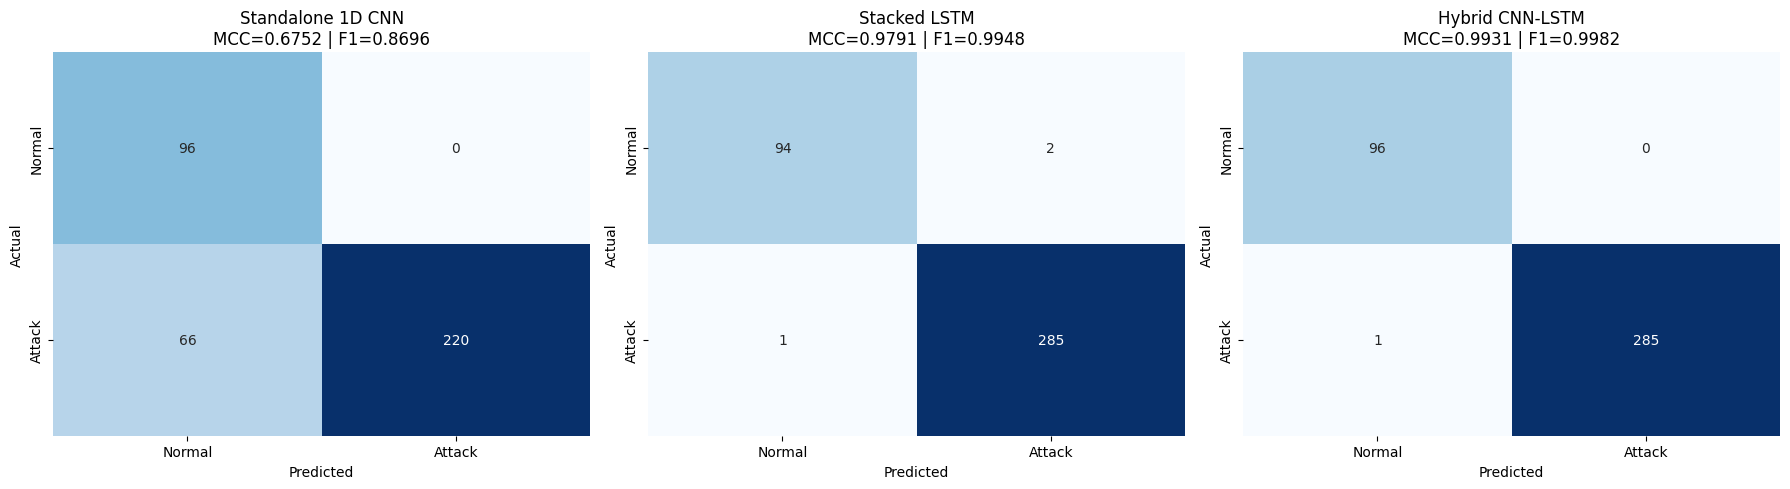

In [ ]:
# ============================================================
# CELL 16 — PHASE 6.2 : Confusion matrices
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, r in zip(axes, results):
    sns.heatmap(r['cm'], annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'Attack'],
                yticklabels=['Normal', 'Attack'], ax=ax)
    ax.set_title(f"{r['name']}\nMCC={r['mcc']:.4f} | F1={r['f1']:.4f}")
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices_botiot.png'), dpi=150)
plt.show()

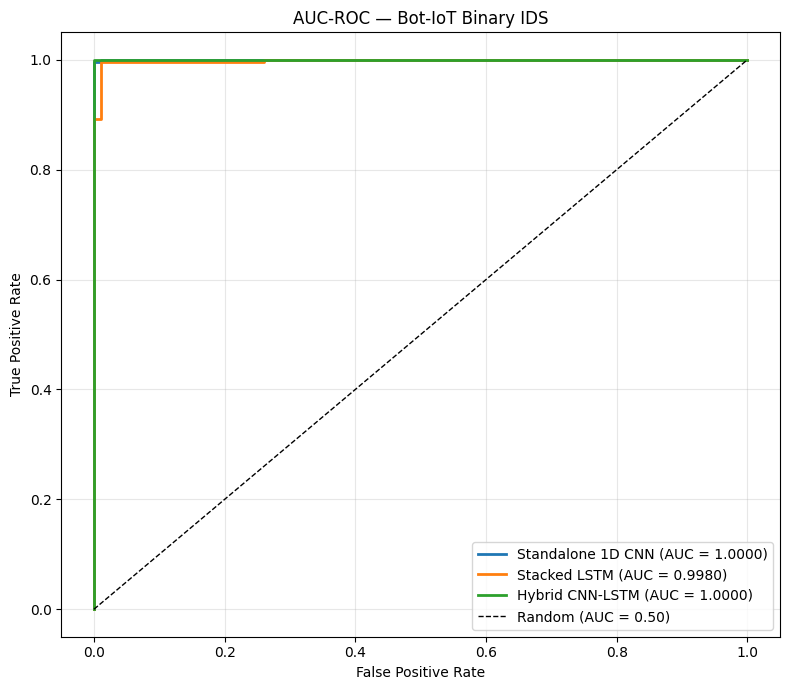

In [ ]:
# ============================================================
# CELL 17 — PHASE 6.2 : AUC-ROC curves (all three overlaid)
# ============================================================
plt.figure(figsize=(8, 7))
for r in results:
    plt.plot(r['fpr'], r['tpr'], lw=2,
             label=f"{r['name']} (AUC = {r['auc']:.4f})")
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.50)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('AUC-ROC — Bot-IoT Binary IDS')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curves_botiot.png'), dpi=150)
plt.show()

In [ ]:
# ============================================================
# CELL 18 — PHASE 6.3 : Edge-readiness summary + save models
# ============================================================
print('\n' + '=' * 70)
print('IoT EDGE-READINESS SUMMARY (Bot-IoT)')
print('=' * 70)
for r in results:
    print(f"{r['name']:<22} | params: {r['params']:>8,} | "
          f"size: {r['size_kb']:>8.2f} KB | "
          f"latency: {r['latency_ms']:>6.3f} ms/flow")

for model, fname in [(cnn_model,    'cnn_ids_botiot.keras'),
                     (lstm_model,   'lstm_ids_botiot.keras'),
                     (hybrid_model, 'hybrid_ids_botiot.keras')]:
    path = os.path.join(OUTPUT_DIR, fname)
    model.save(path)
    print(f'  saved {fname}  ({os.path.getsize(path) / 1024:.1f} KB on disk)')

print('\nPipeline complete.')


IoT EDGE-READINESS SUMMARY (Bot-IoT)
Standalone 1D CNN      | params:   34,049 | size:   133.00 KB | latency:  0.982 ms/flow
Stacked LSTM           | params:   89,345 | size:   349.00 KB | latency:  5.204 ms/flow
Hybrid CNN-LSTM        | params:   35,649 | size:   139.25 KB | latency:  1.976 ms/flow
  saved cnn_ids_botiot.keras  (444.3 KB on disk)
  saved lstm_ids_botiot.keras  (1088.0 KB on disk)
  saved hybrid_ids_botiot.keras  (462.5 KB on disk)

Pipeline complete.


In [ ]:
# ============================================================
# CELL 19 — PHASE 6.3 : TFLite export (fixed for LSTM compatibility)
# ============================================================
import tensorflow as tf
import os

# To fix the 'CudnnRNNV3' error, we ensure the converter handles the LSTM properly.
# In some TF versions, we need to enable Select TF Ops for full coverage.
converter = tf.lite.TFLiteConverter.from_keras_model(hybrid_model)

# Enable standard TFLite ops and the 'Select' ops to handle complex LSTM kernels
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

# Ensure the converter doesn't get stuck on specific sequence ops
converter._experimental_lower_tensor_list_ops = True
converter.optimizations = [tf.lite.Optimize.DEFAULT]

try:
    tflite_quantized_model = converter.convert()

    tflite_path = os.path.join(OUTPUT_DIR, 'hybrid_ids_botiot_edge.tflite')
    with open(tflite_path, 'wb') as f:
        f.write(tflite_quantized_model)

    print(f"TFLite Edge Model saved: {os.path.getsize(tflite_path) / 1024:.1f} KB")
except Exception as e:
    print(f"Conversion failed: {e}")
    print("\nTip: If this still fails, try recreating the model with 'unroll=True' in the LSTM layer.")

Saved artifact at '/tmp/tmppt1dbwbf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20, 1), dtype=tf.float32, name='keras_tensor_68')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135219283136720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000457936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000447760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000458320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000459088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000447568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135218994596176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135219000443728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135218994597136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135218994596752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135218994607504: 

In [ ]:
import pandas as pd, numpy as np
exact = pd.DataFrame(np.asarray(X_test_sel), columns=list(selected_feature_names))
exact['label'] = np.asarray(y_test).astype(int)
exact.to_csv(f'{OUTPUT_DIR}/test_preprocessed_botiot.csv', index=False)
print('Wrote', exact.shape, '-> test_preprocessed_botiot.csv')

Wrote (382, 21) -> test_preprocessed_botiot.csv


In [ ]:
import os
print("Models in memory:", all(n in dir() for n in ['cnn_model','lstm_model','hybrid_model']))
print("Test data in memory:", 'X_test_3d' in dir())
print("Saved .keras files exist:",
      os.path.exists('/content/drive/MyDrive/FYP_Project/models/hybrid_ids.keras'))

Models in memory: False
Test data in memory: True
Saved .keras files exist: True
